# Konijn in Meijendel: historie en hotspots

Stand: 21 oktober 2026. Alleen-lezen analyse van de levende lokale database. Natura 2000-analysescope; M66 en M91 blijven buiten de inhoudelijke kavelanalyse. Alle bronlagen zijn geïnventariseerd; alleen toegelaten waarnemingen worden voor plaatsgebonden conclusies gebruikt.

De konijnenregistraties tijdens BMP-rondes zijn sterk afgenomen. In de negentien voldoende vaak gevolgde kavels ligt het gemiddelde geregistreerde aantal per ronde in 2021–2025 94,7% onder 2009–2013. Dit is een beschrijvende vergelijking binnen de geregistreerde rondes, geen schatting dat de werkelijke populatie precies met dat percentage is gedaald. Kavel 42 is het duidelijkste recente zwaartepunt; kavel 41 valt op in de kortere reeks 2024–2025.

Dit bestand bewaart alle berekeningen, ook nuluitkomsten en ontbrekende dekking. Geen bronregels zijn samengevoegd tot een ontdubbeld aantal dieren. Geen databasewijziging, zware export of VPS-publicatie.


## Bronnen en werkwijze

Konijn wordt geselecteerd via het centrale taxon 38949, *Oryctolagus cuniculus*. De 128 centrale routes controleren ook bronverwijzingen en afgeleide regels. Die zijn geen onafhankelijke waarnemingen.

Primaire reeks: SOVON/AVIMAP-puntregels en oorspronkelijke bezoekmatrix, regelversie `sovon-avimap-daz-v1`. Alleen `voorlopig_bruikbaar` is opgenomen in de bezoekvergelijking. Een nul binnen die selectie betekent geen konijn geregistreerd binnen een ronde met minstens één zoogdiermelding. Zonder zoogdiermelding is geen nul afgeleid. Deelnameselectie en ongewijzigde registratie-intensiteit zijn niet onafhankelijk bewezen.

NDFF: uitsluitend canonieke analyseview met keten `ndff-analyseketen-v1`, besluitversie v4 en doelbereik v2, selectie `voorlopig_bruikbaar` plus Natura 2000-scope. LOS blijft `niet_beoordeeld`, ObsIdentify `voorwaardelijk`; alleen positieve geregistreerde aanwezigheid is bruikbaar. De route-/sectieloze 17.209-laag en ruimtelijk uitgesloten records blijven broncontext.

Telwaarden tijdens herhaalde bezoeken worden als **telsom** getoond, nooit als unieke dieren of dichtheid. Kavels verschillen in omvang, toegankelijkheid, tijdstip en telinspanning. De kaart geeft een gemiddelde per geregistreerde ronde, geen populatiedichtheid of formeel statistisch getoetst cluster.

Voor de vergelijking van dezelfde kavels gelden minimaal vijftien rondes en drie jaren per kavel in zowel 2009–2013 als 2021–2025. Ieder van de negentien kavels weegt even zwaar. Een gevoeligheidsanalyse beperkt beide perioden tot maart–juni. Een aanvullende 500-meter-RD-rasteranalyse beschrijft concentraties van exacte positieve punten, zonder ontbrekende rasterbezoeken als nul te tellen.

Uitvoering: open vanuit de projectmap met Python 3, matplotlib en shapely. De lokale MySQL-loginroute moet al door de eigenaar zijn ingericht. Er is geen wachtwoord in dit bestand opgenomen. Omdat hier geen Jupyter-uitvoerpakket beschikbaar is, zijn de cellen met een Python AST-runner van boven naar beneden uitgevoerd; tabellen en figuren zijn in het notebook opgeslagen.


In [1]:
import sys,json,subprocess,csv,io,datetime
from pathlib import Path
assert (Path.cwd()/"gis/scripts").is_dir(), "Open vanuit de projectmap Meijendel"
sys.path.insert(0,str(Path.cwd()/"gis/scripts"))
from import_external_ecology_sources import CentralQueryDatabase,central_query_routes,central_taxon_query
OUT=Path.cwd()
SOURCES={}
db=CentralQueryDatabase()
def fetch(name,sql):
 args=db.args.copy();args.remove("--skip-column-names")
 r=subprocess.run(args,input="START TRANSACTION READ ONLY;\n"+sql+"\nCOMMIT;",text=True,capture_output=True)
 if r.returncode: raise RuntimeError(name+": "+r.stderr)
 rows=list(csv.DictReader(io.StringIO(r.stdout),delimiter="\t"))
 SOURCES[name]={"query":sql,"executed_at":datetime.datetime.now(datetime.timezone.utc).isoformat(),"rows":rows}
 print(name,len(rows),flush=True)
 return rows

import os,tempfile
os.environ.setdefault('MPLCONFIGDIR',tempfile.mkdtemp(prefix='konijn-matplotlib-'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':130,'savefig.dpi':160})

def show_table(rows,columns=None):
    if not rows: print('(geen regels)'); return
    cols=columns or list(rows[0])
    print(' | '.join(cols))
    for r in rows:
        print(' | '.join(str(round(r.get(k),3)) if isinstance(r.get(k),float) else str(r.get(k,'')) for k in cols))


### Centrale broninventarisatie

In [2]:
routes=central_query_routes(db.schema()); counts=[]
for table,route in routes.items():
 if route['kind']=='staging': continue
 sql=central_taxon_query(table,route,38949).strip().rstrip(';')
 n=int(db.sql('SELECT COUNT(*) '+sql[sql.index('FROM taxa t'): ]+';'))
 if n: counts.append({'table':table,'count':n,'role':route.get('role',route['kind'])})
assert len(routes)==128, "Nieuwe routes: beoordeel eerst bronsemantiek"
print('Gecontroleerde centrale routes:',len(routes)); show_table(counts)


Gecontroleerde centrale routes: 128
table | count | role
daz_bmp_bezoek_taxon | 3262 | afgeleide_meting
daz_bmp_recordkandidaat | 2157 | bronverwijzing
daz_bmp_recordselectie | 4742 | bronverwijzing
ndff_braakbal_hokjaar_taxon | 1 | afgeleide_meting
ndff_braakbal_recordselectie | 1 | bronverwijzing
ndff_konijn_hokdatum_taxon | 4389 | soortreferentie
ndff_konijn_recordselectie | 5095 | bronverwijzing
ndff_open_pq_koppeling | 23260 | bronverwijzing
ndff_open_ruimtelijke_beoordeling | 11630 | bronverwijzing
ndff_open_soortgroep_koppeling | 11630 | bronverwijzing
ndff_open_waarneming | 11630 | bronwaarneming
ndff_open_waarneming_protocol | 11630 | bronverwijzing
ndff_protocol_soort_geschiktheid | 4 | soortreferentie
ndff_soorten | 1 | catalogue
ndff_zoogdieren_overig | 11630 | bronverwijzing
soorten | 1 | catalogue
sovon_avimap_daz_bezoek_taxon | 4354 | afgeleide_meting
sovon_avimap_ndff_daz_koppeling | 4742 | bronverwijzing
sovon_avimap_taxon | 1 | catalogue
sovon_avimap_waarneming | 1000

### Alleen-lezen bronselecties en herkomst

In [3]:
fetch('plots',"SELECT plot_id,kavel_nummer,plot_naam,ST_Area(geom)/10000 area_ha,ST_AsText(geom) wkt FROM v_meijendel_analyseplot_actueel ORDER BY plot_id;")
fetch('visits',"SELECT a.*,p.kavel_nummer,MONTH(a.bezoekdatum) maand FROM v_sovon_avimap_daz_analyse a JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=a.plot_id WHERE a.wetenschappelijke_naam='Oryctolagus cuniculus';")
fetch('points',"SELECT w.batch_id,w.bron_waarneming_id,w.bron_bezoek_id,w.plot_id,p.kavel_nummer,w.jaar,w.maand,w.waarnemingsdatum,w.aantal,w.in_plot,w.x_coord,w.y_coord,w.lopend_jaar,ST_Intersects(w.geom,p.geom) binnen_actuele_geom FROM sovon_avimap_waarneming w JOIN sovon_avimap_import_batch i ON i.batch_id=w.batch_id AND i.actueel=1 JOIN sovon_avimap_taxon t ON t.batch_id=w.batch_id AND t.soortgroep_code=w.soortgroep_code AND t.soortnr=w.soortnr JOIN taxa_bronkoppeling tb ON tb.koppeling_id=t.taxon_bronkoppeling_id JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=w.plot_id WHERE tb.taxon_id=38949;")
fetch('annual_summary',"SELECT m.*,v.plot_id,p.kavel_nummer,v.jaar,v.bezoek_datum bezoekdatum FROM daz_bmp_bezoek_taxon m JOIN taxa_bronkoppeling t ON t.koppeling_id=m.taxon_bronkoppeling_id JOIN dagbezoeken_bmp v ON v.bezoek_id=m.bezoek_id JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=v.plot_id WHERE t.taxon_id=38949 AND m.reconstructieversie='sovon-bmp-jaarbestanden-v1';")
fetch('legacy_bmp',"SELECT r.*,v.jaar,v.plot_id,v.bezoekdatum,p.kavel_nummer,k.koppelstatus sovon_overlap FROM daz_bmp_recordselectie r JOIN ndff_soorten s ON s.wetenschappelijke_naam=r.wetenschappelijke_naam JOIN taxa_bronkoppeling tb ON tb.koppeling_id=s.taxon_bronkoppeling_id JOIN daz_bmp_bezoek v ON v.bezoek_id=r.bezoek_id AND v.reconstructieversie=r.reconstructieversie JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=v.plot_id LEFT JOIN sovon_avimap_ndff_daz_koppeling k ON k.ndff_waarneming_id=r.waarneming_id WHERE tb.taxon_id=38949 AND r.koppelstatus='eenduidig_bmp_bezoek' AND (k.koppelstatus IS NULL OR k.koppelstatus NOT LIKE 'sovon_vervangt_ndff%');")
fetch('ndff_coverage',"SELECT * FROM Meijendel_ndff_secure.v_ndff_gebruiksdekking_soortgroep_protocol WHERE soortgroep_raw LIKE '%Zoog%' AND protocol_sleutel IN ('17.209','17.204','LOS','102.006','14.204','17.005','17.002');")
fetch('ndff_inventory',"SELECT a.protocol_sleutel,a.record_selectiestatus,a.gegevensgeschiktheid,a.kwaliteitsmelding,MIN(a.jaar) eerste_jaar,MAX(a.jaar) laatste_jaar,COUNT(*) records FROM Meijendel_ndff_secure.v_ndff_analyse_record a WHERE a.wetenschappelijke_naam='Oryctolagus cuniculus' GROUP BY 1,2,3,4;")
fetch('ndff_local',"SELECT a.*,p.kavel_nummer,w.periode_start,w.telonderwerp,w.aantal_raw,w.schaal_telmethode,w.vervaagd,ST_Area(w.openbare_geometrie) oppervlakte_m2,ST_AsText(w.openbare_geometrie) wkt FROM Meijendel_ndff_secure.v_ndff_analyse_record a JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=CAST(a.plot_id AS UNSIGNED) JOIN ndff_open_waarneming w ON w.waarneming_id=a.open_waarneming_id WHERE a.wetenschappelijke_naam='Oryctolagus cuniculus' AND a.record_selectiestatus='voorlopig_bruikbaar';")
fetch('nem_year',"SELECT w.jaar,COUNT(*) bronrecords,COUNT(DISTINCT DATE(w.periode_start)) kalenderdatums,COUNT(DISTINCT w.openbare_geometrie_sha256) hokken,SUM(r.daz_overlapstatus='mogelijke_overlap_17_204') mogelijke_overlap FROM ndff_konijn_recordselectie r JOIN ndff_open_waarneming w ON w.waarneming_id=r.waarneming_id JOIN ndff_soorten s ON s.soort_key=w.soort_key JOIN taxa_bronkoppeling b ON b.koppeling_id=s.taxon_bronkoppeling_id WHERE b.taxon_id=38949 GROUP BY w.jaar ORDER BY w.jaar;")
fetch('nem_space',"SELECT MIN(w.hoknummer) hok,MIN(w.jaar) eerste_jaar,MAX(w.jaar) laatste_jaar,COUNT(*) bronrecords,COUNT(DISTINCT w.jaar) jaren,ST_AsText(w.openbare_geometrie) wkt FROM ndff_konijn_recordselectie r JOIN ndff_open_waarneming w ON w.waarneming_id=r.waarneming_id JOIN ndff_soorten s ON s.soort_key=w.soort_key JOIN taxa_bronkoppeling b ON b.koppeling_id=s.taxon_bronkoppeling_id WHERE b.taxon_id=38949 GROUP BY w.openbare_geometrie_sha256,ST_AsText(w.openbare_geometrie) ORDER BY COUNT(*) DESC;")
fetch('scope_inventory',"SELECT p.kavel_nummer,sc.in_scope,MIN(w.jaar) eerste,MAX(w.jaar) laatste,COUNT(*) records FROM sovon_avimap_waarneming w JOIN sovon_avimap_taxon t ON t.batch_id=w.batch_id AND t.soortgroep_code=w.soortgroep_code AND t.soortnr=w.soortnr JOIN taxa_bronkoppeling b ON b.koppeling_id=t.taxon_bronkoppeling_id JOIN plots p ON p.plot_id=w.plot_id LEFT JOIN plot_analyse_scope sc ON sc.plot_id=p.plot_id AND sc.scope_code='meijendel_natura2000' WHERE b.taxon_id=38949 GROUP BY 1,2;")

fetch('name_geometries',"SELECT o.object_id,o.voorkeursnaam,o.objectklasse,ST_AsText(g.geometry) wkt FROM nameninventaris_object o JOIN nameninventaris_geometrie g ON g.object_id=o.object_id WHERE o.objectklasse IN ('gebied','functioneel_gebied');")
fetch('hotspot_names',"SELECT o.object_id,o.voorkeursnaam,COUNT(*) puntregels,SUM(w.aantal) telsom,COUNT(DISTINCT w.jaar) jaren FROM sovon_avimap_waarneming w JOIN sovon_avimap_taxon t USING(batch_id,soortgroep_code,soortnr) JOIN taxa_bronkoppeling tb ON tb.koppeling_id=t.taxon_bronkoppeling_id JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=w.plot_id JOIN nameninventaris_geometrie g ON ST_Intersects(w.geom,g.geometry) JOIN nameninventaris_object o ON o.object_id=g.object_id WHERE tb.taxon_id=38949 AND w.in_plot=1 AND w.jaar BETWEEN 2021 AND 2025 AND o.objectklasse='gebied' GROUP BY o.object_id,o.voorkeursnaam ORDER BY COUNT(*) DESC;")
fetch('ndff_year_all',"SELECT a.jaar,a.protocol_sleutel,a.record_selectiestatus,COUNT(*) bronrecords FROM Meijendel_ndff_secure.v_ndff_analyse_record a WHERE a.wetenschappelijke_naam='Oryctolagus cuniculus' GROUP BY 1,2,3 ORDER BY 1,2,3;")
fetch('ndff_overlap',"SELECT n.open_waarneming_id,n.jaar,n.plot_id,COUNT(DISTINCT w.bron_waarneming_id) sovon_matches FROM Meijendel_ndff_secure.v_ndff_analyse_record n JOIN ndff_open_waarneming o ON o.waarneming_id=n.open_waarneming_id JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=CAST(n.plot_id AS UNSIGNED) JOIN sovon_avimap_waarneming w ON w.plot_id=CAST(n.plot_id AS UNSIGNED) AND w.waarnemingsdatum=DATE(o.periode_start) AND ST_Intersects(w.geom,o.openbare_geometrie) JOIN sovon_avimap_taxon t ON t.batch_id=w.batch_id AND t.soortgroep_code=w.soortgroep_code AND t.soortnr=w.soortnr JOIN taxa_bronkoppeling b ON b.koppeling_id=t.taxon_bronkoppeling_id WHERE n.wetenschappelijke_naam='Oryctolagus cuniculus' AND n.record_selectiestatus='voorlopig_bruikbaar' AND b.taxon_id=38949 GROUP BY 1,2,3;")

fetch('summary_reconciliation',"SELECT v.jaar,COUNT(*) samenvattingen,SUM(a.bron_bezoek_id IS NULL) zonder_puntenbezoek,SUM(a.bron_bezoek_id IS NOT NULL AND m.aantal<>a.binnen_som) afwijkend_binnen,SUM(a.bron_bezoek_id IS NOT NULL AND m.aantal+m.aantal_buiten_plot<>a.alle_som) afwijkend_totaal FROM daz_bmp_bezoek_taxon m JOIN taxa_bronkoppeling b ON b.koppeling_id=m.taxon_bronkoppeling_id JOIN dagbezoeken_bmp v ON v.bezoek_id=m.bezoek_id JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=v.plot_id LEFT JOIN (SELECT w.bron_bezoek_id,SUM(IF(w.in_plot=1,w.aantal,0)) binnen_som,SUM(w.aantal) alle_som FROM sovon_avimap_waarneming w JOIN sovon_avimap_taxon t USING(batch_id,soortgroep_code,soortnr) JOIN taxa_bronkoppeling tb ON tb.koppeling_id=t.taxon_bronkoppeling_id WHERE tb.taxon_id=38949 GROUP BY w.bron_bezoek_id) a ON a.bron_bezoek_id=v.bezoek_id WHERE b.taxon_id=38949 AND m.reconstructieversie='sovon-bmp-jaarbestanden-v1' GROUP BY v.jaar;")
fetch('point_names_byplot',"SELECT p.kavel_nummer,o.voorkeursnaam,COUNT(*) punten FROM sovon_avimap_waarneming w JOIN sovon_avimap_taxon t USING(batch_id,soortgroep_code,soortnr) JOIN taxa_bronkoppeling b ON b.koppeling_id=t.taxon_bronkoppeling_id JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=w.plot_id JOIN nameninventaris_geometrie g ON ST_Intersects(w.geom,g.geometry) JOIN nameninventaris_object o ON o.object_id=g.object_id WHERE b.taxon_id=38949 AND w.in_plot=1 AND w.jaar BETWEEN 2021 AND 2025 AND p.kavel_nummer IN ('M42','M41','M34','M33','M31') GROUP BY 1,2;")


plots 67
visits 4144
points 9704
annual_summary 1733
legacy_bmp 323
ndff_coverage 7
ndff_inventory 9
ndff_local 753
nem_year 39
nem_space 11
scope_inventory 46
name_geometries 46
hotspot_names 15
ndff_year_all 150
ndff_overlap 5
summary_reconciliation 21
point_names_byplot 22


### Jaaruitkomsten, perioden en dezelfde kavels

In [4]:
import collections,math,statistics
def load(n):return SOURCES[n]['rows']
def num(r,k):return int(r[k])
points=load('points');visits=load('visits');ndff=load('ndff_local');summaries=load('annual_summary');legacy=load('legacy_bmp');plots={r['kavel_nummer']:r for r in load('plots')}
assert len({(r['batch_id'],r['bron_waarneming_id']) for r in points})==len(points)
assert len({(r['batch_id'],r['bron_bezoek_id']) for r in visits})==len(visits)
assert len({r['canonieke_identiteit_sha256'] for r in ndff})==len(ndff)
assert all(r['in_plot']==r['binnen_actuele_geom'] for r in points)
vp={(r['batch_id'],r['bron_bezoek_id']):r for r in visits}
pointvisit=collections.defaultdict(list)
for r in points:
 if r['in_plot']=='1':pointvisit[(r['batch_id'],r['bron_bezoek_id'])].append(r)
valid=[r for r in visits if r['record_selectiestatus']=='voorlopig_bruikbaar']
for r in visits:
 ps=pointvisit.get((r['batch_id'],r['bron_bezoek_id']),[])
 r['n_within']=sum(num(p,'aantal') for p in ps)
 r['n_points_within']=len(ps)
 r['year']=num(r,'jaar')
 r['month']=num(r,'maand')
def metric(rs):
 n=len(rs);s=sum(r['n_within'] for r in rs);pos=sum(r['n_within']>0 for r in rs)
 return {'visits':n,'positive_visits':pos,'sum':s,'points':sum(r['n_points_within'] for r in rs),'rate':s/n if n else None,'frequency_pct':100*pos/n if n else None,'plots':len({r['plot_id'] for r in rs}),'years':len({r['year'] for r in rs})}
annual=[]
for year in sorted({r['year'] for r in valid}):annual.append({'year':year,**metric([r for r in valid if r['year']==year])})
periods=[('2009–2013',2009,2013),('2014–2018',2014,2018),('2019–2023',2019,2023),('2024–2025',2024,2025)]
periodstats=[{'period':p,**metric([r for r in valid if a<=r['year']<=b])} for p,a,b in periods]
rankings={}
for label,a,b in [('historical',2009,2025),('recent',2021,2025),('last_two',2024,2025),('early',2009,2013)]:
 rr=[]
 for k in sorted(plots):
  rs=[r for r in valid if r['kavel_nummer']==k and a<=r['year']<=b]
  if rs:rr.append({'plot':k,'name':plots[k]['plot_naam'],'area_ha':plots[k]['area_ha'],**metric(rs)})
 rankings[label]=sorted(rr,key=lambda r:r['sum'],reverse=True)
cohort=[]
for k in plots:
 early=[r for r in valid if r['kavel_nummer']==k and 2009<=r['year']<=2013]
 recent=[r for r in valid if r['kavel_nummer']==k and 2021<=r['year']<=2025]
 if len(early)>=15 and len(recent)>=15 and len({r['year'] for r in early})>=3 and len({r['year'] for r in recent})>=3:
  e=metric(early);l=metric(recent);cohort.append({'plot':k,'early':e,'recent':l,'difference':l['rate']-e['rate']})
cohort.sort(key=lambda r:r['difference'])
cohort_summary={'plots':len(cohort),'decreasing':sum(r['difference']<0 for r in cohort),'increasing':sum(r['difference']>0 for r in cohort),'equal':sum(r['difference']==0 for r in cohort),'early_mean_plot_rate':statistics.mean(r['early']['rate'] for r in cohort),'recent_mean_plot_rate':statistics.mean(r['recent']['rate'] for r in cohort)}
cohort_summary['change_pct']=100*(cohort_summary['recent_mean_plot_rate']/cohort_summary['early_mean_plot_rate']-1)
# March-June controls season; equal plot weights avoid changing plot mix.
season=[]
for c in cohort:
 k=c['plot'];e=[r for r in valid if r['kavel_nummer']==k and 2009<=r['year']<=2013 and 3<=r['month']<=6];l=[r for r in valid if r['kavel_nummer']==k and 2021<=r['year']<=2025 and 3<=r['month']<=6]
 if len(e)>=10 and len(l)>=10:season.append({'plot':k,'early':metric(e),'recent':metric(l)})
season_stats={'plots':len(season),'early_mean_plot_rate':statistics.mean(r['early']['rate'] for r in season),'recent_mean_plot_rate':statistics.mean(r['recent']['rate'] for r in season)}
season_stats['change_pct']=100*(season_stats['recent_mean_plot_rate']/season_stats['early_mean_plot_rate']-1)
# fixed-period ratios by plot, no NEM totals mixed in
# spatial count concentration in 500m grid; positive exact points only.
grids={}
for label,a,b in [('historical',2009,2025),('recent',2021,2025),('last_two',2024,2025)]:
 gg=collections.defaultdict(list)
 for r in points:
  if r['in_plot']=='1' and a<=num(r,'jaar')<=b:
   gg[(num(r,'x_coord')//500*500,num(r,'y_coord')//500*500)].append(r)
 grids[label]=[]
 for (x,y),ps in gg.items():
  grids[label].append({'x':x,'y':y,'sum':sum(num(r,'aantal') for r in ps),'records':len(ps),'visits':len({(r['batch_id'],r['bron_bezoek_id']) for r in ps}),'years':len({r['jaar'] for r in ps}),'first':min(r['jaar'] for r in ps),'last':max(r['jaar'] for r in ps),'plots':','.join(sorted({r['kavel_nummer'] for r in ps}))})
 grids[label].sort(key=lambda r:r['records'],reverse=True)
ndffyear=[]
for y in sorted({num(r,'jaar') for r in ndff}):
 rs=[r for r in ndff if num(r,'jaar')==y]
 ndffyear.append({'year':y,'records':len(rs),'subjects':dict(collections.Counter(r['telonderwerp'] for r in rs)),'plots':len({r['plot_id'] for r in rs})})
ndffplot=[]
for k in plots:
 rs=[r for r in ndff if r['kavel_nummer']==k]
 if rs:ndffplot.append({'plot':k,'records':len(rs),'recent_records':sum(2021<=num(r,'jaar')<=2025 for r in rs),'recent_live':sum(2021<=num(r,'jaar')<=2025 and r['telonderwerp']=='levend exemplaar' for r in rs),'first':min(num(r,'jaar') for r in rs),'last':max(num(r,'jaar') for r in rs),'subjects':dict(collections.Counter(r['telonderwerp'] for r in rs))})
ndffplot.sort(key=lambda r:r['records'],reverse=True)
# preserved summaries remain supplementary positive events, no invented negatives.
summaryyear=[]
for y in sorted({num(r,'jaar') for r in summaries}):
 rs=[r for r in summaries if num(r,'jaar')==y]
 summaryyear.append({'year':y,'positive_visit_totals':len(rs),'sum':sum(num(r,'aantal') for r in rs),'outside_sum':sum(num(r,'aantal_buiten_plot') for r in rs),'plots':len({r['plot_id'] for r in rs})})
legacyyear=[]
for y in sorted({num(r,'jaar') for r in legacy}):
 rs=[r for r in legacy if num(r,'jaar')==y]
 legacyyear.append({'year':y,'records':len(rs),'sum':sum(num(r,'aantal_exact') for r in rs),'plots':len({r['plot_id'] for r in rs}),'visits':len({r['bezoek_id'] for r in rs})})
checks={'points_in_scope':len(points),'inside_complete':sum(r['in_plot']=='1' and r['lopend_jaar']=='0' for r in points),'outside_complete':sum(r['in_plot']=='0' and r['lopend_jaar']=='0' for r in points),'partial_points':sum(r['lopend_jaar']=='1' for r in points),'valid_visits':len(valid),'manual_visits':[r for r in visits if r['record_selectiestatus']=='handmatige_controle_bezoekduur'],'partial':metric([r for r in visits if r['record_selectiestatus']=='uitgesloten_lopend_jaar']),'full':metric(valid),'ndff_subjects':dict(collections.Counter(r['telonderwerp'] for r in ndff)),'other_months':dict(collections.Counter(r['maand'] for r in valid))}
result={'checks':checks,'annual':annual,'periods':periodstats,'rankings':rankings,'cohort':cohort,'cohort_summary':cohort_summary,'season_cohort':season,'season_summary':season_stats,'grids':grids,'ndff_year':ndffyear,'ndff_plot':ndffplot,'summary_year':summaryyear,'legacy_year':legacyyear}

print('Jaartabel:'); show_table(annual)
print('Perioden:'); show_table(periodstats)
print('Dezelfde kavels:'); print(cohort_summary)
print('Maart–juni:'); print(season_stats)

Jaartabel:
year | visits | positive_visits | sum | points | rate | frequency_pct | plots | years
2009 | 182 | 148 | 955 | 955 | 5.247 | 81.319 | 21 | 1
2010 | 139 | 111 | 739 | 739 | 5.317 | 79.856 | 19 | 1
2011 | 177 | 129 | 985 | 798 | 5.565 | 72.881 | 23 | 1
2012 | 220 | 170 | 1190 | 857 | 5.409 | 77.273 | 26 | 1
2013 | 222 | 184 | 1104 | 960 | 4.973 | 82.883 | 28 | 1
2014 | 199 | 158 | 1479 | 1108 | 7.432 | 79.397 | 27 | 1
2015 | 265 | 192 | 1176 | 945 | 4.438 | 72.453 | 31 | 1
2016 | 230 | 185 | 1696 | 939 | 7.374 | 80.435 | 33 | 1
2017 | 244 | 162 | 1059 | 666 | 4.34 | 66.393 | 36 | 1
2018 | 213 | 155 | 899 | 535 | 4.221 | 72.77 | 29 | 1
2019 | 173 | 109 | 678 | 304 | 3.919 | 63.006 | 26 | 1
2020 | 235 | 120 | 464 | 250 | 1.974 | 51.064 | 29 | 1
2021 | 254 | 102 | 385 | 193 | 1.516 | 40.157 | 32 | 1
2022 | 229 | 54 | 243 | 100 | 1.061 | 23.581 | 36 | 1
2023 | 270 | 43 | 155 | 69 | 0.574 | 15.926 | 39 | 1
2024 | 302 | 44 | 147 | 69 | 0.487 | 14.57 | 39 | 1
2025 | 284 | 26 | 128 | 

De telsom daalt van 1.696 in 2016 naar 128 in 2025, terwijl de geselecteerde rondes stijgen van 230 naar 284. Het gemiddelde daalt van 7,37 naar 0,45 per ronde; de frequentie van rondes met konijnen van 80,4% naar 9,2%. Omdat dekking en registratie kunnen veranderen, is dit geen gebiedsdekkende populatie-index. De vergelijking van dezelfde negentien kavels ondersteunt wel een breed gedragen afname: achttien dalen, één blijft nul, geen stijgt.


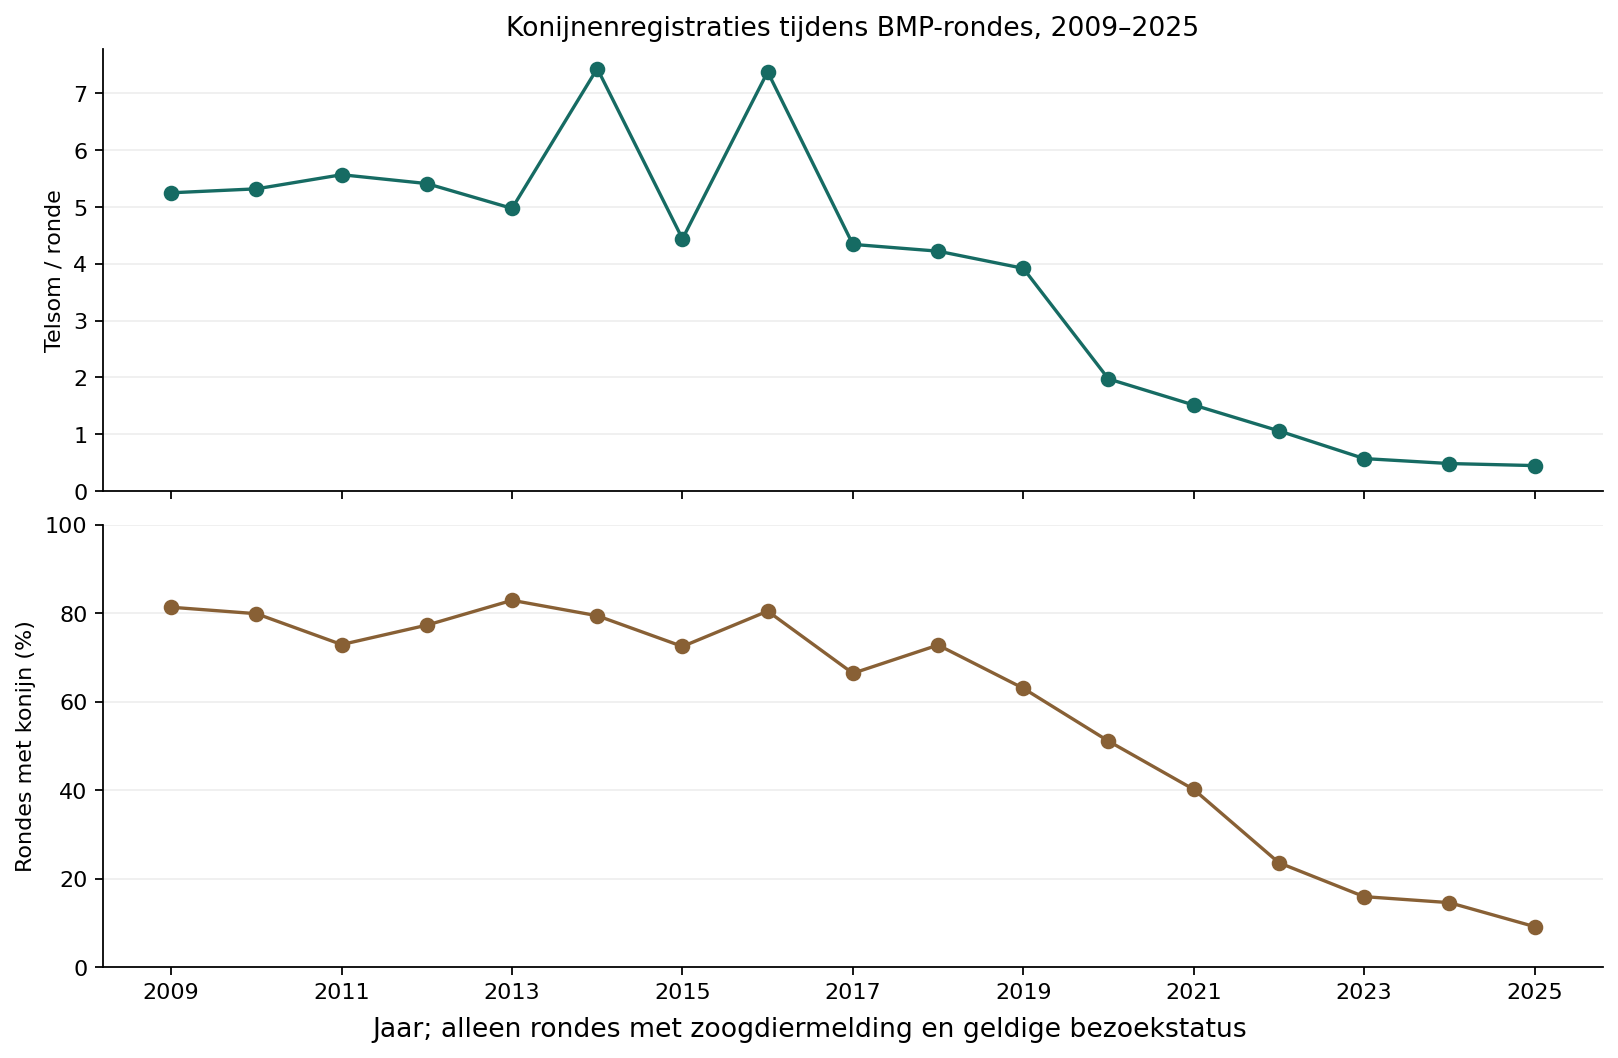

In [5]:
fig,axs=plt.subplots(2,1,figsize=(10,6.5),sharex=True,layout='constrained')
axs[0].plot([r['year'] for r in annual],[r['rate'] for r in annual],marker='o',color='#166b63')
axs[0].set_ylabel('Telsom / ronde');axs[0].set_ylim(bottom=0)
axs[0].set_title('Konijnenregistraties tijdens BMP-rondes, 2009–2025')
axs[1].plot([r['year'] for r in annual],[r['frequency_pct'] for r in annual],marker='o',color='#886035')
axs[1].set_ylabel('Rondes met konijn (%)');axs[1].set_ylim(0,100);axs[1].set_xticks(list(range(2009,2026,2)))
for ax in axs:ax.grid(axis='y',alpha=.2)
fig.supxlabel('Jaar; alleen rondes met zoogdiermelding en geldige bezoekstatus')
fig


### Hotspots per kavel: historische en recente verschillen

In [6]:
for label in ['historical','early','recent','last_two']:
    print('Periode:',label);show_table(rankings[label],['plot','visits','positive_visits','sum','points','rate','frequency_pct','years'])

Periode: historical
plot | visits | positive_visits | sum | points | rate | frequency_pct | years
M42 | 132 | 85 | 2520 | 279 | 19.091 | 64.394 | 12
M75 | 155 | 125 | 1501 | 1176 | 9.684 | 80.645 | 17
M10-12-76 | 181 | 129 | 1487 | 1487 | 8.215 | 71.271 | 17
M17a | 147 | 120 | 1030 | 844 | 7.007 | 81.633 | 17
M77 | 158 | 111 | 748 | 577 | 4.734 | 70.253 | 17
M15 | 122 | 84 | 538 | 337 | 4.41 | 68.852 | 17
M75a | 118 | 97 | 514 | 364 | 4.356 | 82.203 | 16
M2 | 161 | 117 | 465 | 308 | 2.888 | 72.671 | 17
M12a | 160 | 92 | 414 | 392 | 2.587 | 57.5 | 17
M8 | 122 | 83 | 414 | 403 | 3.393 | 68.033 | 13
M14 | 49 | 30 | 299 | 271 | 6.102 | 61.224 | 6
M63 | 108 | 56 | 278 | 262 | 2.574 | 51.852 | 13
M83 | 165 | 89 | 263 | 228 | 1.594 | 53.939 | 17
M17b | 70 | 51 | 243 | 213 | 3.471 | 72.857 | 13
M3 | 152 | 82 | 241 | 231 | 1.586 | 53.947 | 17
M84 | 93 | 46 | 218 | 217 | 2.344 | 49.462 | 11
M35 | 115 | 67 | 206 | 202 | 1.791 | 58.261 | 15
M7 | 134 | 67 | 203 | 178 | 1.515 | 50.0 | 16
M62 | 90 | 

Kavel 42 bevat in 2021–2025 623 van de 1.058 getelde konijnen (58,9%), verdeeld over 35 positieve rondes in vijf jaren. De grootste dagtelsom bedraagt 36 en verklaart dit totaal niet alleen. In 2024–2025 komen 192 van de 275 getelde konijnen uit kavel 42 (69,8%). Het gemiddelde van kavel 42 daalt zelf van 25,53 per ronde in 2014–2018 naar 10,93 in 2021–2025 en 6,62 in 2024–2025. Het is een resterend zwaartepunt, geen aangetoond herstelgebied.

Kavel 41 bevat 27 getelde konijnen tijdens 13 van 14 rondes in 2024–2025. Deze korte telreeks bewijst geen recente vestiging. Kavel 34 bevat in 2021–2025 nog 77 getelde konijnen, maar slechts vijf in 2024–2025. Kavel 31 heeft 36 getelde konijnen in 2021–2023; voor 2024–2025 ontbreekt hier zoogdierbezoekdekking.

De namen worden niet aan hele kavels gelijkgesteld. Van de recente punten in kavel 42 liggen 24 van 95 binnen het geregistreerde Koningsbosch; alle 95 liggen in Delfland. In kavel 33 liggen 30 van 45 punten in Oostduinpark; in kavel 31 33 van 36. Gebiedspolygonen overlappen en de aantallen mogen niet bij elkaar worden opgeteld.


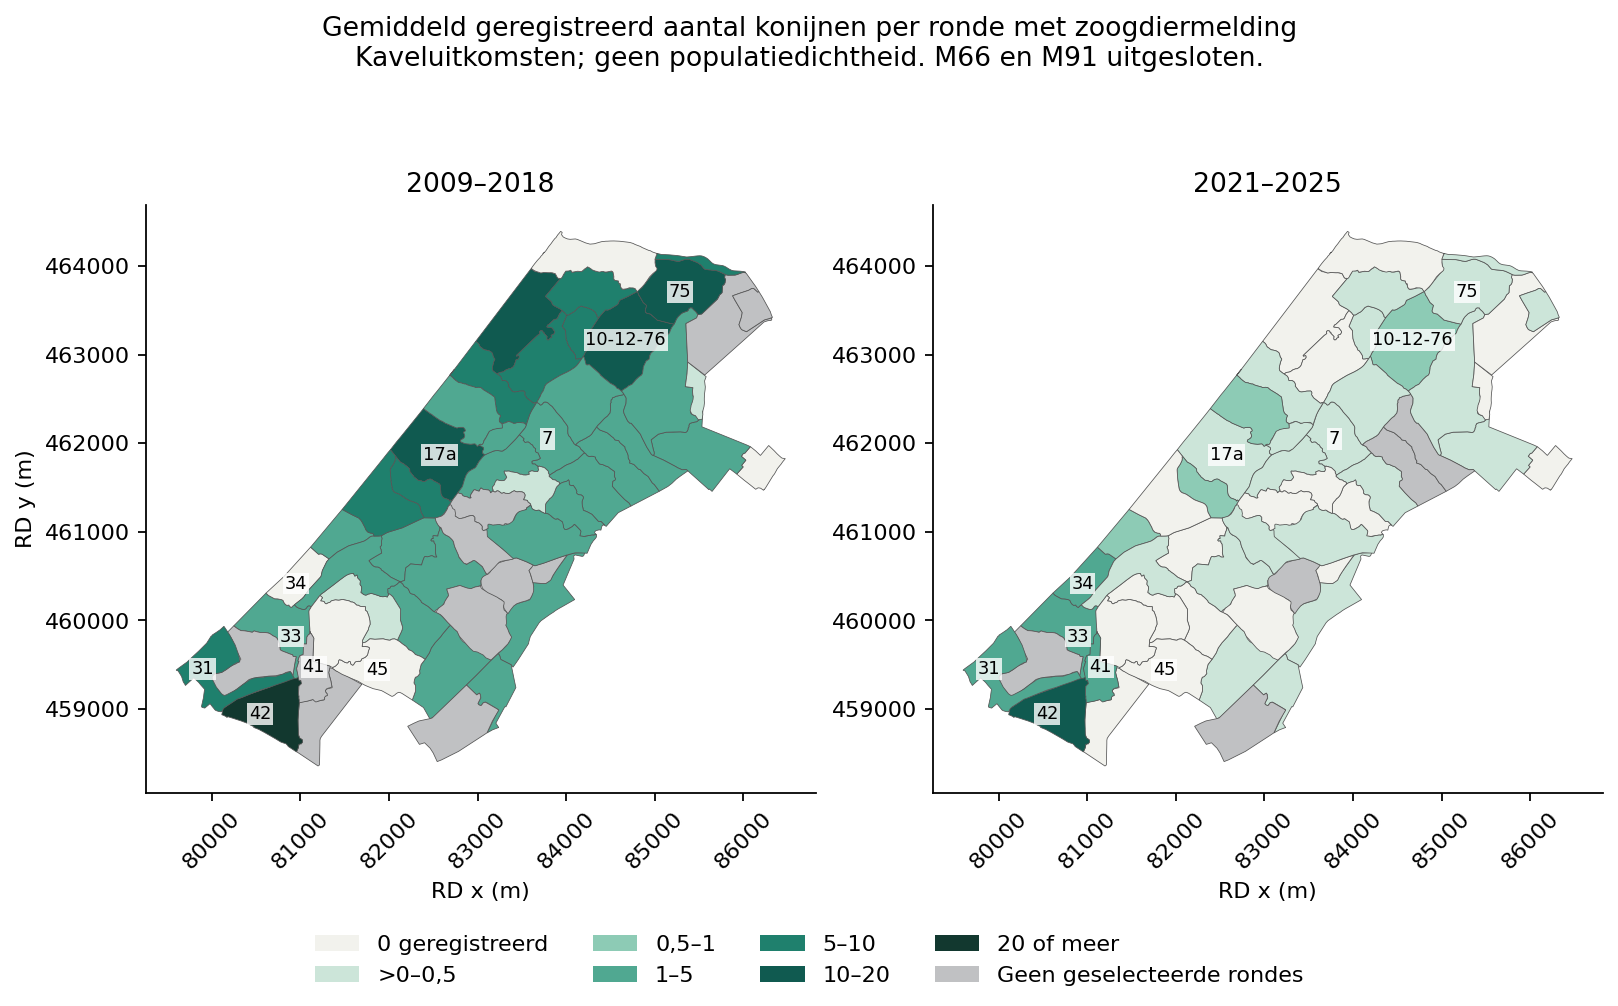

In [7]:
from shapely import wkt
from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch
from matplotlib.colors import BoundaryNorm,ListedColormap

def geometry_path(geom):
    verts=[];codes=[]
    polygons=list(geom.geoms) if geom.geom_type=='MultiPolygon' else [geom]
    for poly in polygons:
        for ring in [poly.exterior,*poly.interiors]:
            coords=list(ring.coords);verts.extend(coords);codes.extend([MPath.MOVETO]+[MPath.LINETO]*(len(coords)-2)+[MPath.CLOSEPOLY])
    return MPath(verts,codes)

bounds=[0,.001,.5,1,5,10,20,1000]
cmap=ListedColormap(['#f2f2ed','#cce5d9','#8dcbb5','#50a891','#1f806d','#105a50','#12382f']);norm=BoundaryNorm(bounds,cmap.N)
fig,axs=plt.subplots(1,2,figsize=(10,6.2),layout='constrained')
for ax,(label,a,b) in zip(axs,[('2009–2018',2009,2018),('2021–2025',2021,2025)]):
    for k,plot in plots.items():
        if plot['wkt']=='NULL':continue
        geom=wkt.loads(plot['wkt']);rs=[r for r in valid if r['kavel_nummer']==k and a<=r['year']<=b];m=metric(rs)
        col=cmap(norm(m['rate'])) if rs else '#c0c1c3'
        ax.add_patch(PathPatch(geometry_path(geom),facecolor=col,edgecolor='#555555',linewidth=.35))
        if k in {'M42','M41','M34','M33','M31','M17a','M75','M10-12-76','M7','M45'}:
            c=geom.representative_point();ax.annotate(k.replace('M',''),(c.x,c.y),fontsize=8,ha='center',va='center',bbox={'facecolor':'white','edgecolor':'none','alpha':.8,'pad':.8})
    ax.autoscale_view();ax.set_aspect('equal');ax.set_title(label);ax.set_xlabel('RD x (m)');ax.tick_params(axis='x',rotation=45)
axs[0].set_ylabel('RD y (m)')
from matplotlib.patches import Patch
legend=[Patch(facecolor=cmap(i),label=t) for i,t in enumerate(['0 geregistreerd','>0–0,5','0,5–1','1–5','5–10','10–20','20 of meer'])]+[Patch(facecolor='#c0c1c3',label='Geen geselecteerde rondes')]
fig.legend(handles=legend,loc='outside lower center',ncol=4,frameon=False)
fig.suptitle('Gemiddeld geregistreerd aantal konijnen per ronde met zoogdiermelding\nKaveluitkomsten; geen populatiedichtheid. M66 en M91 uitgesloten.',fontsize=12)
fig


### Vergelijking van dezelfde negentien kavels

In [8]:
show_table([{'plot':r['plot'],'early_visits':r['early']['visits'],'recent_visits':r['recent']['visits'],'early_rate':r['early']['rate'],'recent_rate':r['recent']['rate'],'difference':r['difference']} for r in cohort])

plot | early_visits | recent_visits | early_rate | recent_rate | difference
M75 | 54 | 33 | 13.278 | 0.485 | -12.793
M17a | 50 | 36 | 12.52 | 0.472 | -12.048
M10-12-76 | 49 | 57 | 12.571 | 0.649 | -11.922
M77 | 51 | 38 | 7.255 | 0.158 | -7.097
M8 | 39 | 37 | 7.0 | 0.162 | -6.838
M75a | 49 | 17 | 6.98 | 0.235 | -6.744
M17b | 22 | 31 | 5.364 | 0.677 | -4.686
M15 | 38 | 26 | 4.816 | 0.154 | -4.662
M2 | 53 | 39 | 4.245 | 0.333 | -3.912
M3 | 41 | 48 | 2.707 | 0.0 | -2.707
M12a | 44 | 49 | 2.727 | 0.122 | -2.605
M6 | 33 | 29 | 2.242 | 0.069 | -2.173
M83 | 53 | 43 | 2.17 | 0.209 | -1.961
M7 | 30 | 44 | 1.733 | 0.114 | -1.62
M46 | 45 | 51 | 1.422 | 0.0 | -1.422
M71 | 19 | 36 | 1.421 | 0.278 | -1.143
M61 | 18 | 26 | 0.889 | 0.0 | -0.889
M35 | 26 | 43 | 1.0 | 0.698 | -0.302
M1a | 17 | 38 | 0.0 | 0.0 | 0.0


### Historische aanvulling vóór AVIMAP en bronvergelijking

In [9]:
print('Aanvullend bewaarde SOVON-bezoektotalen, geen onafhankelijke optelling:');show_table(summaryyear)
print('Historische eenduidig gekoppelde NDFF/BMP-bronrecords zonder SOVON-vervanging:');show_table(legacyyear)
print('Vergelijking SOVON-jaarbestanden met AVIMAP binnen/buiten plot:');show_table(SOURCES['summary_reconciliation']['rows'])

Aanvullend bewaarde SOVON-bezoektotalen, geen onafhankelijke optelling:
year | positive_visit_totals | sum | outside_sum | plots
2005 | 37 | 186 | 0 | 7
2006 | 64 | 384 | 0 | 10
2007 | 69 | 494 | 0 | 12
2008 | 48 | 365 | 0 | 9
2009 | 110 | 728 | 16 | 20
2010 | 76 | 478 | 23 | 18
2011 | 85 | 669 | 14 | 18
2012 | 128 | 862 | 10 | 22
2013 | 132 | 792 | 25 | 24
2014 | 114 | 953 | 8 | 19
2015 | 145 | 902 | 14 | 24
2016 | 135 | 1208 | 11 | 25
2017 | 111 | 725 | 10 | 24
2018 | 114 | 530 | 5 | 23
2019 | 74 | 426 | 2 | 19
2020 | 74 | 222 | 0 | 20
2021 | 70 | 223 | 3 | 20
2022 | 32 | 119 | 1 | 16
2023 | 44 | 156 | 0 | 16
2024 | 44 | 147 | 0 | 13
2025 | 27 | 128 | 1 | 10
Historische eenduidig gekoppelde NDFF/BMP-bronrecords zonder SOVON-vervanging:
year | records | sum | plots | visits
2005 | 22 | 72 | 5 | 12
2006 | 40 | 164 | 9 | 25
2007 | 73 | 524 | 12 | 47
2008 | 62 | 406 | 11 | 44
2009 | 12 | 43 | 5 | 11
2010 | 3 | 12 | 3 | 3
2011 | 7 | 17 | 4 | 7
2012 | 5 | 12 | 4 | 5
2013 | 8 | 16 | 6 | 8
2

De SOVON-jaarbestanden leveren binnen scope voor 2005–2008 218 positieve bezoektotalen met telsom 1.429. Er is geen volledige historische nulmatrix; deze totalen dragen geen vergelijkbare gemiddelde telreeks. Alle 1.515 binnen scope bewaarde totalen uit 2009–2025 stemmen exact overeen met de AVIMAP-puntsommen, zowel binnen plot als inclusief buiten-plotwaarden. Ze worden niet opgeteld.

De 323 eenduidig gereconstrueerde NDFF/BMP-bronregels zonder vastgelegde SOVON-vervanging blijven secundair. Ook hier betekent geen vastgelegde overlap geen bewezen onafhankelijke waarneming. Zij worden niet bij AVIMAP of jaarbestanden opgeteld en leveren geen nieuwe nullen.

De oudste ruimtelijk toegelaten losse melding betreft één dood konijn uit 1960. De toegelaten meldingen van levende dieren beginnen in 1995. De afzonderlijke 17.209-levering omvat 5.095 positieve sectieregels uit 1984–2023, op elf kilometerhokken. Ze toont dat de bronhistorie verder teruggaat, maar route- en sectie-id ontbreken en alle regels blijven uitgesloten van de kavelanalyse. Het ontbreken van 1999 in deze levering betekent geen afwezigheid van konijnen. In 2023 zijn slechts vijf hokken vertegenwoordigd, tegenover tien in 2016; de afname van bronregels kan niet los van die veranderende dekking worden gelezen.


In [10]:
print('17.209: bronrecords, kalenderdatums en hokken; geen bezoeken of dieren:');show_table(SOURCES['nem_year']['rows'])
print('Canonieke NDFF-selectie en uitsluitingen:');show_table(SOURCES['ndff_inventory']['rows'],['protocol_sleutel','record_selectiestatus','gegevensgeschiktheid','eerste_jaar','laatste_jaar','records'])
print('Toegelaten aanvullende NDFF-meldingen per jaar:');show_table(ndffyear)
print('Toegelaten aanvullende NDFF-meldingen per kavel:');show_table(ndffplot)
print('Mogelijke bronoverlap, geen bewezen dubbelingen:');show_table(SOURCES['ndff_overlap']['rows'])

17.209: bronrecords, kalenderdatums en hokken; geen bezoeken of dieren:
jaar | bronrecords | kalenderdatums | hokken | mogelijke_overlap
1984 | 68 | 8 | 8 | 0
1985 | 87 | 10 | 8 | 0
1986 | 83 | 10 | 8 | 0
1987 | 135 | 17 | 8 | 0
1988 | 105 | 13 | 8 | 0
1989 | 129 | 15 | 8 | 0
1990 | 108 | 13 | 8 | 0
1991 | 126 | 16 | 8 | 0
1992 | 135 | 30 | 9 | 0
1993 | 146 | 24 | 9 | 0
1994 | 155 | 23 | 10 | 0
1995 | 151 | 25 | 10 | 0
1996 | 97 | 20 | 10 | 0
1997 | 159 | 27 | 10 | 0
1998 | 72 | 8 | 9 | 0
2000 | 80 | 11 | 10 | 0
2001 | 82 | 19 | 9 | 0
2002 | 139 | 23 | 10 | 0
2003 | 87 | 19 | 10 | 0
2004 | 97 | 18 | 10 | 0
2005 | 153 | 21 | 10 | 1
2006 | 181 | 25 | 10 | 0
2007 | 169 | 25 | 10 | 0
2008 | 191 | 26 | 10 | 0
2009 | 188 | 26 | 10 | 0
2010 | 186 | 22 | 10 | 0
2011 | 165 | 22 | 10 | 0
2012 | 186 | 27 | 10 | 0
2013 | 183 | 25 | 10 | 0
2014 | 189 | 24 | 10 | 0
2015 | 181 | 27 | 10 | 0
2016 | 176 | 25 | 10 | 0
2017 | 153 | 26 | 9 | 1
2018 | 150 | 26 | 9 | 0
2019 | 129 | 27 | 9 | 2
2020 | 138 | 3

De toegelaten NDFF-selectie bevat 753 regels: 724 levende exemplaarmeldingen, vijftien dode dieren en veertien spoor-, mest- en vraatmeldingen. Voor levende meldingen betreft het 1995–2025, voor dood 1960–2018 en voor sporen 2010–2024. De vijf mogelijke AVIMAP/LOS-overlapparen blijven herkenbaar. NDFF-regelaantallen zijn geen aantallen dieren en geen trendmaat.

In 2021–2025 bevat kavel 42 daarnaast 114 losse levende meldingen, kavel 41 23 en kavel 31 21. Dit ondersteunt de locatie van de registratiezwaartepunten, maar vormt geen onafhankelijke populatieschatting: waarnemers, bezoektijdstippen en toegankelijkheid kunnen overlappen met BMP.


### Rasterconcentraties en alle ontbrekende of nuluitkomsten

In [11]:
for label in grids:
    print('500m RD-raster:',label);show_table(grids[label])
print('Scopekavels zonder geselecteerd AVIMAP-zoogdierbezoek 2009–2025:');print([k for k in plots if k not in {r['plot'] for r in rankings['historical']}])
print('Kavels met geselecteerde rondes maar geen konijnpunten in 2021–2025:');print([r['plot'] for r in rankings['recent'] if r['sum']==0])
print('Partieel 2026:');print(checks['partial'])
print('Alle controle-uitkomsten:');print({k:v for k,v in checks.items() if k!='manual_visits'})

500m RD-raster: historical
x | y | sum | records | visits | years | first | last | plots
84000 | 463000 | 721 | 700 | 126 | 16 | 2009 | 2025 | M10-12-76,M13,M14,M77
85000 | 463500 | 769 | 604 | 109 | 14 | 2009 | 2024 | M12a,M75
84500 | 463000 | 503 | 501 | 99 | 15 | 2009 | 2023 | M10-12-76,M75
82000 | 461500 | 547 | 436 | 139 | 17 | 2009 | 2025 | M17a,M17b
84000 | 462500 | 428 | 424 | 135 | 14 | 2009 | 2023 | M10-12-76,M13,M14,M8
85000 | 464000 | 528 | 367 | 154 | 13 | 2009 | 2021 | M75,M75a
85500 | 463500 | 454 | 352 | 146 | 15 | 2009 | 2024 | M74,M75,M75a
84000 | 463500 | 456 | 350 | 98 | 15 | 2009 | 2024 | M13,M77
84500 | 463500 | 319 | 277 | 138 | 13 | 2009 | 2021 | M10-12-76,M75,M77
82500 | 461500 | 299 | 271 | 97 | 14 | 2009 | 2023 | M17a,M17b,M6
83000 | 462500 | 383 | 251 | 84 | 10 | 2009 | 2020 | M13s,M14,M15,M16
83500 | 462500 | 258 | 238 | 68 | 10 | 2009 | 2022 | M14,M15,M8
84000 | 461000 | 207 | 206 | 81 | 10 | 2009 | 2019 | M62,M63
83500 | 462000 | 198 | 174 | 94 | 14 | 200

De 500-metercel RD x=80.500–81.000, y=459.000–459.500 bevat in 2021–2025 58 puntregistraties tijdens 36 bezoeken, verspreid over vijf jaren; de cel raakt M31, M33, M41 en M42. De naastgelegen zuidelijke cel x=80.500–81.000, y=458.500–459.000 bevat dertig punten met telsom 310 tijdens 23 bezoeken in vijf jaren, alle in M42. Het vaste raster is een beschrijving van registratieconcentraties. Telroutes binnen rastercellen ontbreken, zodat geen ruimtelijke nulmatrix of formele hotspot-significantie kan worden vastgesteld.

Voor 2026 bevat de onvolledige bron tot 19 juli dertig positieve punten in elf kavels, met telsom 78 tijdens 23 van 305 rondes met zoogdiermelding in 44 kavels. Kavel 42 levert 55 van de 78. Dit jaar blijft buiten de vergelijkingen met volledige jaren.

Bij één bezoek in M17b, 22 juni 2023, staat een duur van 1.580 minuten. De positieve melding van één konijn blijft bewijs van aanwezigheid; het bezoek is uit de vergelijkende noemer gehouden. Daardoor bevat de complete positieve kaartbron 9.539 punten (telsom 13.483), en de vergelijkende reeks 9.538 punten (telsom 13.482) tijdens 3.838 bezoeken. De 135 buiten-plotpunten uit 2009–2025 zijn niet in lokale kavelhotspots meegeteld; de bronvlag binnen plot stemt bij alle 9.704 in-scope puntregels overeen met de actuele geometrie.

De audits `--audit-live`, `--audit-konijnen` en `--audit-sovon-avimap` zijn op 21 oktober 2026 geslaagd. Zij bewijzen technische sluiting, geen complete populatiedekking. Er is geen populatietrendmodel, dichtheidsmodel, formele hotspottoets of causaal beheereffectmodel geschat: daarvoor ontbreken respectievelijk gevalideerde detectie/inspanning, ruimtelijke bezoekdekking en de uitgevoerde uitzet-/vrijlatingsgegevens. De gegevens laten wel een breed gedragen geregistreerde afname en enkele resterende zwaartepunten zien.


## Literatuurduiding, habitat en mogelijke bescherming door mensen

Aanvulling op 21 oktober 2026 op verzoek van Ton. Ton beschrijft M42 als open kavel aan de rand van Meijendel, met veel mensen en verkeer langs de grenzen. Dit is expliciete terreinkennis van Ton, geen gemeten historische recreatie- of verkeersreeks. De hypothese dat mensen of verkeer predatoren kunnen afschrikken, of wandelaars hun jacht verstoren, is opgenomen naast habitatkwaliteit, zichtbaarheid en gewenning van vossen.

### Welke Zotero-bronnen zijn daadwerkelijk gelezen?

De lokale Zotero-API is alleen-lezen geraadpleegd. De inventaris bevat 1.520 items. De fulltextroute noemt 800 bijlagen; van 418 geeft de API tekst terug, bij 382 geeft dezelfde route HTTP 404. Dat laatste bewijst niet dat de oorspronkelijke bijlage ontbreekt. In de 418 beschikbare teksten zijn 166 bijlagen gevonden met konijn, rabbit of Oryctolagus. Duplicaten, tijdschriftnummers met meerdere artikelen, trefwoordenlijsten en ongerelateerde vermeldingen zijn niet als 166 onderzoeken behandeld. Alleen de onderstaande geselecteerde werken dragen de inhoudelijke duiding. Er zijn geen paden of bestanden op de T7 of NAS geopend, geen Zotero-items gewijzigd en geen literaire tabelgegevens aan de waarnemingsdatabase toegevoegd.

| Werk en oorspronkelijke tekst | Zotero-herkomst | Wat het toevoegt; grens van het bewijs |
|---|---|---|
| Lucas (1990), *Konijnensterfte in Meijendel*, Meijendel Mededelingen 19: 76–77 | Artikelitem `5FGF663X`; gelezen in nummeritem `MZVIKR47`, bijlage `MTMA73DQ` | Beschrijft sterfte vanaf december 1989 en gemiddelden over tien routes, voorjaar 1984–voorjaar 1990. De oorzaak was bij schrijven nog onbekend. Latere RHD-duiding wordt niet als toenmalige diagnose gepresenteerd. De OCR-tabellen zijn niet zonder visuele controle opnieuw gedigitaliseerd. |
| Bankert & In ’t Groen (2003), *Konijnen in de duinen van Meijendel*, Holland’s Duinen 42: 5–11 | Artikelitem `573XJMG5`; gelezen in nummeritem `QN3SBRM4`, bijlage `RT3DNRBU` | Vijf telwegsecties en aansluitende achterlandproefvlakken, oktober 2001–februari 2002. Zichttellingen bleken verstoringsgevoelig. Keutelonderzoek wees in deze beperkte wintersituatie op circa 30% meer konijnen in het achterland. Geen universele correctiefactor voor BMP, andere jaren of M42. |
| Van Strien et al. (2011), *Occupancy dynamics … with imperfect detection*, Wildlife Research 38: 717–725, DOI 10.1071/WR11050 | `47FPXWLC`, bijlage `PNRIDHD5` | 245 transecten, Nederlandse kustduinen 1984–2009. Detectie verschilt tussen jaren en habitats; herstel en herkolonisatie verschillen eveneens. Dit ondersteunt het onderscheid tussen zichtbaarheid en voorkomen; de landelijke uitkomsten worden niet aan M42 toegeschreven. |
| Dekker et al. (2022), *Herstel konijnenpopulaties in de kustduinen*, OBN-2017-86-DK | Bijlage `A9C2QLFG` onder item `PFCUAJ48` | Hoofdrapport bij het werkprotocol. Bemonstering in de winters 2018/2019 en 2019/2020; bloedmonsters uit 23 deelgebieden. Virussen blijven een belangrijke beperking. Korte, voedselrijke kruiden-/grasvegetatie, dekking en holen hangen samen met geschiktheid. Relatief gezonde populaties komen ook in door mensen beïnvloede leefgebieden voor, zonder bewijs dat mensen de oorzaak van dat succes zijn. |
| Van der Hagen (2022), *Rabbits Rule*, proefschrift, DOI 10.18174/575460 | `U5HPG8GI`, bijlage `973AJYRN` | Langjarige synthese over konijnen, vee en vegetatie in Meijendel. De verandering van de vegetatie heeft meerdere oorzaken. Geen onafhankelijke herhaling van alle analyses die later als artikel verschenen. |
| Van der Hagen et al. (2023), *The role of livestock grazing in long-term vegetation changes …*, Plant Sociology 60: 1–12, DOI 10.3897/PLS2023601/01 | `XJFRZYF8`, bijlage `WH2RWN2G` | 41 permanente vegetatieplots vanaf de jaren 1950. Koppelt verlies van konijnenbegrazing aan verdere struweel- en bosontwikkeling. Vee in de onderzochte bezetting vervulde niet vanzelf dezelfde functie. Geen meting van begrazingsdruk of draagkracht in M42. |
| Van der Hagen (2025), *Een konijnenexclosure uit 1976 en de vegetatieontwikkeling sedertdien*, Holland’s Duinen 87: 6–12 | Artikelitem `IQ38WJ9U`; gelezen in nummeritem `RPXR4YWJ`, bijlage `K2KDJXNG` | Acht exclosures aangelegd in 1976; artikel volgt één noordhellingexclosure en omgeving met beelden uit 1978, 2002 en 2025. Onderstreept het langjarige effect van konijnen op vegetatiestructuur. Het Zotero-jaar 1976 is hier het aanlegjaar, niet het publicatiejaar; de bron is november 2025. |
| De Kok (2016), *Vossenwaarnemingen in de Hollandse duinen*, Holland’s Duinen 67: 14–16 | Nummeritem `6XR2Q2G3`, bijlage `CC6YF2XM` | Ruim 800 waarnemingen gedurende de voorafgaande vijf jaar, in Meijendel en Berkheide. Beschrijft verschillen in schuwheid en vossen die op de Harstenhoek blijven liggen of jagen terwijl mensen buiten het hek passeren. Observationele terreinkennis, geen verstoringsexperiment of rechtstreekse kavel-42-toets. |
| De Kok (2018), *Vossen van de Harstenhoek, drie jaar nestobservaties*, Holland’s Duinen 72: 33–35 | Nummeritem `TIJHLKKU`, bijlage `VHG9RFMM` | Nestobservaties uit 2016–2018 beschrijven zowel gewenning aan voorbijgangers als mogelijke gevolgen van opdringerige fotografen. Aanwezigheid buiten een hek verschilt van benadering of betreding. Geen bewezen afname van de predatie op konijnen. |

De documentidentiteit is op de tekst zelf gecontroleerd. Bij `PFCUAJ48` heeft het parent-item de titel Werkprotocol, maar de gelezen PDF is het langere hoofdrapport. Het publicatiejaar van de exclosurepublicatie is met de oorspronkelijke tijdschriftkop en WUR-registratie als 2025 vastgesteld. Beide afwijkingen zijn in deze analyse verantwoord; Zotero-metadata zijn niet stilzwijgend gewijzigd.

### Wat verandert de literatuur aan het historische beeld?

De AVIMAP-reeks begint pas in 2009. De literatuur plaatst die reeks in een langere geschiedenis: myxomatose in Meijendel rond 1954, een in december 1989 beschreven nieuwe sterftegolf, gedeeltelijk herstel en herkolonisatie in delen van de Nederlandse duinen na 2003, en RHDV-2 in Nederland vastgesteld in 2015 volgens Dekker et al. (2022). De verschillen tussen 1989 en circa 1990 in latere RHD-beschrijvingen zijn geen exacte datering van een laboratoriumdiagnose per kavel.

De eigen geregistreerde afname van 7,37 konijnen per ronde in 2016 (230 rondes) naar 0,45 in 2025 (284 rondes) past bij een breder patroon van ziekte en moeilijk herstel. De database bevat geen gekoppelde ziekteuitslagen die bewijzen dat RHDV-2 die specifieke lokale afname heeft veroorzaakt. De negentien-kavelvergelijking en de beperking tot maart–juni ondervangen een deel van de wisselende dekking, niet de verschillen in zichtbaarheid en gedrag die Van Strien en Bankert beschrijven.

De ecologische betekenis gaat verder dan aantallen: de exclosures en vegetatiereeksen ondersteunen dat konijnen met begrazing, het eten van kiemplanten en graafwerk een functie vervullen die niet zonder meer door vee wordt overgenomen. De 623 opgetelde konijnenregistraties in M42 uit 2021–2025 bewijzen niet dat daar voldoende konijnen aanwezig zijn om die functie op kavelniveau te vervullen. Begraasd oppervlak, graafactiviteit, reproductie en overleving zijn in deze selectie niet gemeten.

### M42: habitat, zichtbaarheid en de hypothese van predatiebescherming

Er blijven vier verklaringen naast elkaar staan:

- Open en eventueel kortgrazig terrein kan geschikt voedselgebied zijn én konijnen beter zichtbaar maken. Ton bevestigt de openheid; kortgrazigheid, maaibeheer, voedselkwaliteit en holen zijn niet als gemeten M42-kenmerken uit de beschrijving afgeleid.
- Menselijke aanwezigheid kan vossen op bepaalde tijden of plekken tot vermijding brengen of een jacht onderbreken. Het effect zou ook via tijdstippen kunnen lopen: mensen overdag, vossen meer in schemer en nacht.
- Vossen kunnen aan voorspelbare voorbijgangers wennen. De lokale waarnemingen van De Kok laten zien dat mensen langs een hek niet altijd voorkomen dat vossen blijven of jagen. Dat sluit tijdelijke verstoring elders of in andere situaties niet uit.
- Dezelfde omstandigheden kunnen ook konijnen verstoren. Het netto-effect van mensen, honden en verkeer is daarom niet uit de aanwezigheid van mensen alleen af te leiden.

Een aanvullende primaire studie buiten Zotero, Díaz-Ruiz et al. (2016; online 2015), *Drivers of red fox daily activity*, Journal of Zoology 298: 128–138, DOI 10.1111/jzo.12294, onderzocht twaalf Iberische gebieden met cameravallen. Minder dagactiviteit van vossen hing samen met grotere menselijke verstoring. Dit ondersteunt het mogelijke mechanisme van tijdsverschuiving; het onderzoek bewijst geen lager totaal aantal gevangen konijnen in M42. In de onderzochte verstoringscontext speelde ook predatorbestrijding een rol, zodat de uitkomst niet uitsluitend aan wandelaars kan worden toegeschreven. De algemene beschermingshypothese is dus serieus genomen, zonder een lokale uitkomst te veronderstellen.

### Aanvullende controle: liggen de konijnpunten langs de kavelgrens?

De 95 positieve AVIMAP-punten binnen M42 uit 2021–2025 zijn met de actuele kavelgeometrie in EPSG:28992 vergeleken. De afstand is tot de dichtstbijzijnde kavelgrens, niet tot een weg of een wandelaar. De grenzen en stroken zijn gekozen rekenzones, geen gemeten verkeersinvloed.

| Afstand tot kavelgrens | Puntregels binnen de strook | Telsom | Aandeel van de 95 punten | Aandeel kaveloppervlak in strook |
|---|---:|---:|---:|---:|
| 0–25 m | 8 | 9 | 8,4% | 17,5% |
| 0–50 m | 16 | 27 | 16,8% | 33,6% |
| 0–100 m | 37 | 69 | 38,9% | 60,6% |
| 0–150 m | 60 | 208 | 63,2% | 80,5% |

De overige 58 punten, met telsom 554, liggen meer dan honderd meter van de dichtstbijzijnde kavelgrens. Het zwaartepunt in de getelde aantallen ligt daarmee niet uitsluitend direct langs de kavelgrens. Dit bewijst noch weerlegt bescherming door mensen: drukte kan verder doorwerken, de route kan punten selecteren en een administratieve kavelgrens is geen maat voor predatie. Zonder afgelegde telroute is ook de vergelijking met het strookoppervlak geen bewijs van een voorkeur voor de binnenruimte.

### Aanvullende controle: vossen tijdens dezelfde BMP-rondes

De centrale taxonidentiteit Vos is 38970 (*Vulpes vulpes*). Alleen primaire punten binnen de eigen kavel zijn samengevat op dezelfde bruikbare zoogdierbezoeken als in de konijnenanalyse; geen NDFF-vossenbron is erbij opgeteld.

In M42 is in 2021–2025 op 21 van 57 rondes een vos gemeld (36,8%), met telsom 35. In de overige 47 kavels met dekking gaat het om 192 van 1.282 rondes (15,0%), met telsom 237. Dit is een ongecorrigeerde registratievergelijking, geen vergelijking van vossendichtheid of predatiedruk. Openheid kan ook de zichtbaarheid van vossen verhogen; meer konijnen kunnen vossen aantrekken. De uitkomst geeft geen steun aan een eenvoudige verklaring waarin vossen M42 doorgaans mijden. Tijdelijk verstoorde jacht of verschuiving naar de nacht blijft hiermee wel mogelijk.

In 2024–2025 zijn in M42 op vijf van 29 rondes vossen gemeld, met telsom vijf. Dat lagere recente meldingsaantal bewijst geen afgenomen jachtsucces. De volledige vossenjaartabel 2014–2025, alle 48 kaveluitkomsten uit 2021–2025 en de exacte queries staan in het notebook. Er is geen model geschat waarin mensen of verkeer konijnensterfte veroorzaken of voorkomen: gekoppelde bezoekers-/verkeersintensiteit, nachtactiviteit, daadwerkelijke jacht en prooisucces ontbreken in deze analyse.

### Beleids- en beheercontext, gescheiden van uitvoering en bewijs

De duiding is gecontroleerd tegen het lokaal beschikbare vastgestelde Natura 2000-beheerplan 2016–2022 (`CZDA8MMM`), het ontwerp 2026–2032 (`LAW9SJXC`), het actuele provinciale Natuurbeheerplan Zuid-Holland 2027 en de officiële Dunea-uitleg over de functie van het konijn. Het Natuurbeheerplan 2027 is een vastgesteld subsidie- en beheerkaartkader; het is geen gemeten konijnenreeks. De geraadpleegde officiële bekendmaking van 22 januari 2026 noemt het Natura 2000-plan 2026–2032 uitdrukkelijk ontwerp. Het is hier niet als definitief plan of als bewijs van uitvoering gebruikt. Het doel van behoud/herstel van open, soortenrijke duinen ondersteunt het belang van konijnen, maar niet een onbewezen dichtheidsnorm voor M42 of het succes van bijplaatsing. Dunea’s uitleg dat konijnenbegrazing en graverij belangrijk zijn voor het duin wordt ondersteund door de lokale vegetatiestudies.

Primaire externe vindplaatsen, naast de vastgelegde Zotero-identiteiten:

- [Bankert & In ’t Groen (2003), WUR-bronregistratie](https://library.wur.nl/WebQuery/groenekennis/1687088).
- [Van Strien et al. (2011), auteurs-/WUR-registratie](https://research.wur.nl/en/publications/occupancy-dynamics-of-wild-rabits-oryctolagus-cuniculus-in-the-co/).
- [Dekker et al. (2022), hoofdrapport](https://www.natuurkennis.nl/Uploaded_files/Publicaties/obn-2017-86-dk-herstel-konijnenpopulaties-in-kustduinen.pdf).
- [Van der Hagen et al. (2023), WUR-registratie](https://research.wur.nl/en/publications/the-role-of-livestock-grazing-in-long-term-vegetation-changes-in-/).
- [Van der Hagen (2025), oorspronkelijke publicatie](https://edepot.wur.nl/707244).
- [De Kok (2016), oorspronkelijke tijdschriftuitgave](https://www.dunea.nl/duinen/-/media/bestanden/duinen/hollands-duinen/hollandsduinen-nummer-67-dunea.pdf).
- [De Kok (2018), oorspronkelijke tijdschriftuitgave](https://www.dunea.nl/duinen/-/media/bestanden/duinen/hollands-duinen/dunea---hollands-duinen-nummer-72.pdf).
- [Díaz-Ruiz et al. (2016), primaire onderzoeksabstract](https://zslpublications.onlinelibrary.wiley.com/doi/abs/10.1111/jzo.12294).
- [Provinciaal Natuurbeheerplan](https://www.zuid-holland.nl/onderwerpen/natuur-en-landschap/natuurbeheer/natuurbeheerplan-zuid-holland/), [ontwerp Natura 2000-beheerplan](https://zoek.officielebekendmakingen.nl/prb-2026-1161.html) en [Dunea over konijnenbeheer](https://www.dunea.nl/algemeen/nieuws/2022/duinen-missen-natuurlijk-beheer-van-het-konijn).

De gecombineerde conclusie blijft een breed gedragen geregistreerde afname met enkele resterende zwaartepunten. M42 is een duidelijke registratiehotspot in een open, door mensen beïnvloede randligging. Een bijdrage van gunstige habitat, betere zichtbaarheid, gedrag en mogelijk tijdelijke bescherming door mensen is aannemelijk als verklaringenset, maar de aandelen daarvan zijn niet vastgesteld. Alleen openheid en drukte zijn door Ton als terreinkennis bevestigd; bescherming tegen predatoren is een hypothese, geen geconstateerd effect. De gegevens geven evenmin grond om M42 als eenvoudig model voor uitzetting elders te behandelen.


In [12]:
fetch('fox_comparison',"SELECT p.kavel_nummer,COUNT(*) rondes,SUM(COALESCE(f.vossen,0)>0) rondes_met_vos,SUM(COALESCE(f.vossen,0)) vos_telsom,COUNT(DISTINCT a.jaar) jaren FROM v_sovon_avimap_daz_analyse a JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=a.plot_id LEFT JOIN (SELECT w.batch_id,w.bron_bezoek_id,SUM(w.aantal) vossen FROM sovon_avimap_waarneming w JOIN sovon_avimap_taxon t USING(batch_id,soortgroep_code,soortnr) JOIN taxa_bronkoppeling b ON b.koppeling_id=t.taxon_bronkoppeling_id WHERE b.taxon_id=38970 AND w.in_plot=1 GROUP BY w.batch_id,w.bron_bezoek_id) f ON f.batch_id=a.batch_id AND f.bron_bezoek_id=a.bron_bezoek_id WHERE a.wetenschappelijke_naam='Oryctolagus cuniculus' AND a.record_selectiestatus='voorlopig_bruikbaar' AND a.jaar BETWEEN 2021 AND 2025 GROUP BY p.kavel_nummer ORDER BY p.kavel_nummer;")
fetch('fox_m42_year',"SELECT a.jaar,COUNT(*) rondes,SUM(COALESCE(f.vossen,0)>0) rondes_met_vos,SUM(COALESCE(f.vossen,0)) vos_telsom FROM v_sovon_avimap_daz_analyse a JOIN v_meijendel_analyseplot_actueel p ON p.plot_id=a.plot_id LEFT JOIN (SELECT w.batch_id,w.bron_bezoek_id,SUM(w.aantal) vossen FROM sovon_avimap_waarneming w JOIN sovon_avimap_taxon t USING(batch_id,soortgroep_code,soortnr) JOIN taxa_bronkoppeling b ON b.koppeling_id=t.taxon_bronkoppeling_id WHERE b.taxon_id=38970 AND w.in_plot=1 GROUP BY w.batch_id,w.bron_bezoek_id) f ON f.batch_id=a.batch_id AND f.bron_bezoek_id=a.bron_bezoek_id WHERE a.wetenschappelijke_naam='Oryctolagus cuniculus' AND a.record_selectiestatus='voorlopig_bruikbaar' AND p.kavel_nummer='M42' GROUP BY a.jaar ORDER BY a.jaar;")
print('Vossen tijdens dezelfde rondes, alle kavels 2021–2025:')
show_table(SOURCES['fox_comparison']['rows'])
print('M42, volledige vossenjaartabel:')
show_table(SOURCES['fox_m42_year']['rows'])
fox_rows=SOURCES['fox_comparison']['rows']
fox_m42=next(x for x in fox_rows if x['kavel_nummer']=='M42')
fox_other=[x for x in fox_rows if x['kavel_nummer']!='M42']
print('M42:',fox_m42)
print('Overige kavels:',len(fox_other),'rondes',sum(int(x['rondes']) for x in fox_other),'met vos',sum(int(x['rondes_met_vos']) for x in fox_other))
from shapely.geometry import Point
m42_geometry=wkt.loads(plots['M42']['wkt'])
m42_points=[x for x in points if x['kavel_nummer']=='M42' and x['in_plot']=='1' and 2021<=int(x['jaar'])<=2025]
edge_results=[]
for distance in [25,50,100,150]:
    selected=[x for x in m42_points if Point(int(x['x_coord']),int(x['y_coord'])).distance(m42_geometry.boundary)<=distance]
    strip=m42_geometry.difference(m42_geometry.buffer(-distance))
    edge_results.append({'afstand_m':distance,'puntregels':len(selected),'telsom':sum(int(x['aantal']) for x in selected),'punt_aandeel_pct':100*len(selected)/len(m42_points),'oppervlakte_aandeel_pct':100*strip.area/m42_geometry.area})
assert len(m42_points)==95
assert edge_results[2]['puntregels']==37 and edge_results[2]['telsom']==69
print('M42 afstand tot administratieve kavelgrens; geen afstand tot weg of persoon:')
show_table(edge_results)


fox_comparison 48
fox_m42_year 12
Vossen tijdens dezelfde rondes, alle kavels 2021–2025:
kavel_nummer | rondes | rondes_met_vos | vos_telsom | jaren
M10-12-76 | 57 | 11 | 13 | 5
M105 | 21 | 0 | 0 | 5
M12a | 49 | 15 | 16 | 5
M13 | 6 | 0 | 0 | 2
M13s | 1 | 0 | 0 | 1
M14 | 16 | 4 | 6 | 2
M15 | 26 | 1 | 1 | 5
M16 | 25 | 6 | 6 | 5
M16s | 20 | 1 | 3 | 5
M17a | 36 | 8 | 10 | 5
M17b | 31 | 4 | 4 | 5
M1a | 38 | 9 | 9 | 5
M1b | 35 | 2 | 3 | 5
M2 | 39 | 8 | 8 | 5
M3 | 48 | 7 | 9 | 5
M31 | 24 | 1 | 1 | 3
M33 | 45 | 13 | 18 | 5
M34 | 38 | 6 | 12 | 5
M35 | 43 | 17 | 22 | 5
M36 | 6 | 1 | 1 | 3
M4-5 | 34 | 2 | 2 | 5
M41 | 14 | 3 | 3 | 2
M42 | 57 | 21 | 35 | 5
M43 | 1 | 0 | 0 | 1
M45 | 37 | 8 | 9 | 5
M46 | 51 | 8 | 10 | 5
M51 | 21 | 1 | 1 | 3
M52 | 11 | 1 | 1 | 2
M53 | 29 | 1 | 1 | 4
M54b | 6 | 1 | 1 | 1
M55 | 5 | 2 | 3 | 1
M6 | 29 | 0 | 0 | 5
M61 | 26 | 2 | 3 | 4
M62 | 12 | 1 | 1 | 3
M63 | 39 | 11 | 21 | 5
M7 | 44 | 8 | 9 | 5
M71 | 36 | 6 | 7 | 4
M72 | 14 | 0 | 0 | 4
M73 | 8 | 0 | 0 | 2
M74 | 33 | 1 |

### Vastgelegde documentidentiteiten

Hashes betreffen de via de lokale API gelezen indextekst, geen oorspronkelijke PDF-bestanden. Er is geen externe opslag geopend.

In [13]:
literature_provenance=[{'werk': 'Lucas 1990', 'zotero_item': '5FGF663X', 'gelezen_bijlage': 'MTMA73DQ', 'tekst_sha256': '9c442282d798d5105847df06e71bada9b16a92253f5dd0dde9354da20d4ade83'}, {'werk': 'Bankert & In ’t Groen 2003', 'zotero_item': '573XJMG5', 'gelezen_bijlage': 'RT3DNRBU', 'tekst_sha256': 'cf2fdf967914216159d575e52c82d8e9790ce9441632d294fb9e04e90ac9708d'}, {'werk': 'Van Strien et al. 2011', 'zotero_item': '47FPXWLC', 'gelezen_bijlage': 'PNRIDHD5', 'tekst_sha256': 'a675a094ead86ae6697a9dcd7f8b4d15a3f9e9c1a2317d011d4b9d7996138322'}, {'werk': 'Dekker et al. 2022; hoofdrapport', 'zotero_item': 'PFCUAJ48', 'gelezen_bijlage': 'A9C2QLFG', 'tekst_sha256': '4d13a55dd71ab495c77fb822e8f0e15e7b9700e6ad672f719d7df8666c6ba311'}, {'werk': 'Van der Hagen 2022', 'zotero_item': 'U5HPG8GI', 'gelezen_bijlage': '973AJYRN', 'tekst_sha256': 'b5a06cfc405c59ccab9ae11c30d77c228e08c8fbccac8c37aec795629120a974'}, {'werk': 'Van der Hagen et al. 2023', 'zotero_item': 'XJFRZYF8', 'gelezen_bijlage': 'WH2RWN2G', 'tekst_sha256': 'b69d14e1ce8d2ea4cc1ed3e625b5a5e743f277e91f589ea7ebb396610647aa35'}, {'werk': 'Van der Hagen 2025', 'zotero_item': 'IQ38WJ9U', 'gelezen_bijlage': 'K2KDJXNG', 'tekst_sha256': '530c586dfa3b98d251bbfc2dc9b67b2750588a7cea4815ba4ead927f2215d389'}, {'werk': 'De Kok 2016', 'zotero_item': '6XR2Q2G3', 'gelezen_bijlage': 'CC6YF2XM', 'tekst_sha256': '9f3d2fd524537c3e81d356f83208d2cae2e7a3c20ca5172a2b6014afdd95705d'}, {'werk': 'De Kok 2018', 'zotero_item': 'TIJHLKKU', 'gelezen_bijlage': 'VHG9RFMM', 'tekst_sha256': '55bd95cdfa16cf27d4f75710a2497cc7bbc829c3befe55c9d0b5f099beaefdc7'}]
show_table(literature_provenance)

werk | zotero_item | gelezen_bijlage | tekst_sha256
Lucas 1990 | 5FGF663X | MTMA73DQ | 9c442282d798d5105847df06e71bada9b16a92253f5dd0dde9354da20d4ade83
Bankert & In ’t Groen 2003 | 573XJMG5 | RT3DNRBU | cf2fdf967914216159d575e52c82d8e9790ce9441632d294fb9e04e90ac9708d
Van Strien et al. 2011 | 47FPXWLC | PNRIDHD5 | a675a094ead86ae6697a9dcd7f8b4d15a3f9e9c1a2317d011d4b9d7996138322
Dekker et al. 2022; hoofdrapport | PFCUAJ48 | A9C2QLFG | 4d13a55dd71ab495c77fb822e8f0e15e7b9700e6ad672f719d7df8666c6ba311
Van der Hagen 2022 | U5HPG8GI | 973AJYRN | b5a06cfc405c59ccab9ae11c30d77c228e08c8fbccac8c37aec795629120a974
Van der Hagen et al. 2023 | XJFRZYF8 | WH2RWN2G | b69d14e1ce8d2ea4cc1ed3e625b5a5e743f277e91f589ea7ebb396610647aa35
Van der Hagen 2025 | IQ38WJ9U | K2KDJXNG | 530c586dfa3b98d251bbfc2dc9b67b2750588a7cea4815ba4ead927f2215d389
De Kok 2016 | 6XR2Q2G3 | CC6YF2XM | 9f3d2fd524537c3e81d356f83208d2cae2e7a3c20ca5172a2b6014afdd95705d
De Kok 2018 | TIJHLKKU | VHG9RFMM | 55bd95cdfa16cf27d4f75710a2497c